<a href="https://colab.research.google.com/github/ramiro-ing/DL-breast-cancer/blob/version_Tania_28102026/Obligatorio_implementacio%CC%81n_bordes_0_685.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Obligatorio - Taller de Deep Learning - Prueba 1

**Fecha de entrega:** 8/12/2026 hasta las 21:00 (hora de Montevideo). Es también el cierre de la competencia en Kaggle (último envío).
**Puntaje máximo:** 50 puntos

**Integrantes:** [Nombre(s) y Apellido(s)]

## Obligatorio

El objetivo de este obligatorio es evaluar su conocimiento en Deep Learning mediante la implementación completa de un modelo de segmentación de imágenes basado en el paper [**"U-Net: Convolutional Networks for Biomedical Image Segmentation"**](https://arxiv.org/pdf/1505.04597). Toda la implementación debe realizarse desde cero utilizando PyTorch, y los estudiantes tendrán la libertad de ajustar ciertos hiperparámetros y configuraciones mientras mantengan la esencia del paper original.

La tarea de este año es la **segmentación de lesiones mamarias en imágenes de ecografía**: para cada imagen, el modelo debe indicar qué píxeles pertenecen a la lesión.

### **Competencia en Kaggle**

Además, como parte de este obligatorio, participarán en una competencia privada en Kaggle donde se les proporcionará un dataset de test oculto (sin target). Deberán subir sus predicciones a Kaggle y se evaluarán en función de la métrica **Dice Coefficient (Coeficiente de Dice)**. Esta competencia les permitirá comparar sus resultados con los de sus compañeros en un entorno real de evaluación.

Las imágenes de test **provienen de otros centros y fueron adquiridas con otros ecógrafos** que las imágenes de entrenamiento. Por lo tanto, un buen resultado en validación no garantiza un buen resultado en test: el modelo debe **generalizar a un dominio distinto** del que vio durante el entrenamiento.

### **¿Qué es el Dice Coefficient?**
El **Dice Coefficient**, también conocido como F1-score para segmentación, es una métrica utilizada para evaluar la similitud entre la predicción y la anotación manual en tareas de segmentación. Se define de la siguiente manera:

$$
\text{Dice} = \frac{2 \cdot |A \cap B|}{|A| + |B|}
$$

Donde:
- $A$ es el conjunto de píxeles predichos como pertenecientes a la clase positiva.
- $B$ es el conjunto de píxeles verdaderos pertenecientes a la clase positiva.
- $|A \cap B|$ es la intersección de $A$ y $B$, es decir, los píxeles correctamente predichos como positivos.

Un valor de Dice de **1** indica una predicción perfecta, mientras que un valor de **0** indica que no hay coincidencia entre la predicción y el valor verdadero. En la competencia, el Dice se calcula **por imagen** y luego se promedia sobre las imágenes de test. Todas las imágenes de test contienen una lesión, por lo que **la predicción de cada imagen debe tener al menos un píxel de lesión**: si alguna fila tiene la máscara vacía, Kaggle rechaza el envío completo. Para aprobar el obligatorio es necesario obtener un puntaje de al menos **0.65** en la tabla pública de Kaggle.

### **Criterios a Evaluar**

1. **Análisis del Dataset (5 puntos):**
   - Exploración y visualización del dataset para comprender su estructura y características (tamaños de imagen, proporción de píxeles de lesión, pacientes, equipos de adquisición, etc.).
   - Comparación entre los equipos de adquisición del conjunto de entrenamiento, e identificación de las diferencias que pueden afectar al modelo cuando se aplique a imágenes de otros equipos.
   - Justificación de las decisiones tomadas en el preprocesamiento de datos, como el tamaño de entrada del modelo, la normalización, el aumento de datos (data augmentation) y la partición del dataset en conjuntos de entrenamiento y validación.

2. **Implementación Correcta del Modelo U-Net (20 puntos):**
   - Construcción de la arquitectura U-Net siguiendo la estructura descrita en el paper, permitiendo ajustes como el número de filtros, funciones de activación y métodos de inicialización de pesos.
   - Se aceptan mejoras, por ejemplo batch normalization u otras funciones de activación.

3. **Entrenamiento del Modelo (10 puntos):**
   - Configuración adecuada del ciclo de entrenamiento, incluyendo la elección de la función de pérdida y del optimizador (Adam, SGD, etc.).
   - Uso de técnicas de regularización para mejorar la generalización del modelo, como el dropout, batch normalization y data augmentation.
   - Gráficas y análisis de la evolución del entrenamiento, mostrando las curvas de pérdida y métricas relevantes tanto en el conjunto de entrenamiento como en el de validación.
   - Puede utilizarse experimentación con hiperparámetros con Weights & Biases (W&B) para optimizar el rendimiento del modelo. Este punto es opcional, pero se valorará positivamente si se justifica su uso y se presentan resultados claros.

4. **Evaluación de Resultados (10 puntos):**
   - Evaluación exhaustiva del modelo utilizando métricas de segmentación como **Dice Coefficient**.
   - Análisis detallado de los resultados, incluyendo un análisis de errores para identificar y discutir casos difíciles.
   - Análisis del efecto del cambio de dominio: qué tipo de imágenes o lesiones se segmentan peor y por qué.
   - Visualización de ejemplos representativos de segmentaciones correctas e incorrectas, comparando con las etiquetas manuales proporcionadas en el dataset.

5. **Participación y Resultados en la Competencia Kaggle (5 puntos):**
   - Participación activa en la competencia de Kaggle, con al menos un (1) envío de predicciones.
   - Puntaje obtenido en la tabla de posiciones de Kaggle, evaluado en base al **Dice Coefficient** en el conjunto de test oculto. Es necesario obtener al menos **0.65** en la tabla pública para aprobar el obligatorio.

   Notas:
   - **Cualquier decisión debe ser justificada en el notebook.**
   - El **Dice Coefficient** es la métrica utilizada para evaluar el desempeño de los modelos de segmentación en esta competencia.

### **Run-Length Encoding (RLE)**

Dado que no se suben las imágenes segmentadas directamente a Kaggle, se requiere usar **Run-Length Encoding (RLE)** para comprimir las máscaras de predicción en una cadena de texto que será evaluada. El **RLE** es una técnica de compresión donde se representan secuencias consecutivas de píxeles en formato `start length`, indicando la posición de inicio y la longitud de cada secuencia de píxeles positivos.

Para calcular el **RLE**, se sigue el siguiente proceso:

1. Se aplanan las máscaras predichas en un solo vector (por columnas, orden Fortran). La máscara es un array de numpy de forma `(alto, ancho)` con valores 0 y 1.
2. Se identifican los píxeles con valor positivo (1) y se calculan las secuencias consecutivas.
3. Se registra la posición de inicio de cada secuencia (comenzando en 1) y su longitud en formato `start length`.

Este formato comprimido se sube a Kaggle en lugar de las imágenes segmentadas.

**Importante:** no se aceptan máscaras vacías (ver la sección anterior). Las imágenes de test tienen tamaños distintos. La máscara de cada imagen debe codificarse **con el tamaño original de esa imagen**. Si el modelo trabaja con otro tamaño, la predicción debe llevarse de vuelta al tamaño original antes de calcular el RLE.

#### **Ejemplo de RLE**

```python
import numpy as np

def rle_encode(mask):
    pixels = np.array(mask).flatten(order='F')  # Aplanar la máscara en orden Fortran
    pixels = np.concatenate([[0], pixels, [0]])  # Añadir ceros al principio y final
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1  # Encontrar transiciones
    runs[1::2] = runs[1::2] - runs[::2]  # Calcular longitudes
    return ' '.join(str(x) for x in runs)

mask = np.array([[0, 0, 1, 0, 0],
                 [0, 1, 1, 1, 0],
                 [1, 1, 1, 0, 0],
                 [0, 0, 0, 1, 1]])

print(rle_encode(mask))
```

> **Salida:** 3 1 6 2 9 3 14 1 16 1 20 1


### **Sobre el Dataset**

El dataset contiene imágenes de ecografía mamaria en escala de grises, cada una con una lesión (benigna o maligna) segmentada manualmente por especialistas.

- **Entrenamiento** (`train/`): imágenes (`train/images/`) y máscaras binarias (`train/masks/`, con el mismo nombre de archivo que la imagen; 255 = lesión, 0 = fondo). El archivo `train/train.csv` indica, para cada imagen, el paciente (`case`), el equipo de adquisición (`device`) y la patología (`pathology`). Un mismo paciente puede tener más de una imagen: los sufijos `-l` y `-r` del nombre corresponden a dos vistas de la misma lesión, y `-s` a una vista única.
- **Test** (`test/images/`): imágenes sin máscara, de otros centros y otros equipos. Cada imagen de test contiene al menos una lesión. **Las imágenes de test se usan únicamente para generar las predicciones que se envían a Kaggle**: no pueden usarse para entrenar, ajustar ni analizar el modelo.
- Las imágenes se entregan **en su resolución original**, que varía de una imagen a otra. La elección del tamaño de entrada del modelo es parte del trabajo.
- `sample_submission.csv` muestra el formato de la entrega: una fila por imagen de test, con las columnas `id` y `encoded_pixels` (cada fila contiene un único píxel, solo como ejemplo del formato).

### **Reglas de la Competencia**

- **Solo se pueden usar los datos de entrenamiento provistos.** No se permite usar datos externos (incluidas las versiones originales de los datasets citados en la sección *Datos y Atribución*) ni modelos o pesos pre-entrenados: la U-Net se entrena desde cero.
- Cada equipo puede realizar como máximo **dos (2) envíos por día** y debe seleccionar **dos (2)** envíos para la evaluación final.
- La tabla pública se calcula con el 80 % de las imágenes de test y es la que se usa para la aprobación. La posición final se define con el 20 % restante (tabla privada), que se revela al cierre de la competencia.
- **Premio:** el equipo en el primer puesto de la tabla privada recibe un ejemplar del libro [*The Welch Labs Illustrated Guide to AI*](https://www.welchlabs.com/ai-book), siempre que apruebe la defensa del obligatorio respondiendo correctamente al menos cuatro (4) de las cinco (5) preguntas.

### **Instrucciones de Entrega**

- Deberán entregar un Jupyter Notebook (.ipynb) que contenga todo el código y las explicaciones necesarias para ejecutar la implementación, el entrenamiento y la evaluación del modelo.
- **El notebook principal no puede superar las 50 páginas una vez exportado a PDF** (con sus salidas: tablas, gráficas e imágenes). Se corrige el notebook principal; lo que exceda ese límite no se tiene en cuenta.
- Opcionalmente, pueden entregar **notebooks secundarios** con material de apoyo. Por ejemplo, `experimentos_augmentation.ipynb` con todos los entrenamientos de una búsqueda de hiperparámetros: el notebook principal incluye solo la tabla de resultados y las conclusiones, y referencia al secundario para el detalle. Los notebooks secundarios no son obligatorios.
- El notebook debe incluir secciones bien documentadas explicando las decisiones de diseño del modelo, los experimentos realizados, y los resultados obtenidos.
- El código debe estar escrito de manera clara.
- La entrega debe realizarse a través de la plataforma de gestión de ORT (gestion.ort.edu.uy) antes de la fecha límite.

### **Materiales Adicionales**

Para facilitar su trabajo, pueden consultar los siguientes recursos:

- [U-Net: Convolutional Networks for Biomedical Image Segmentation (paper original)](https://arxiv.org/abs/1505.04597)
- [Documentación de PyTorch](https://pytorch.org/docs/stable/index.html)
- [Tutoriales y recursos adicionales en Kaggle](https://www.kaggle.com/)
- [Convolución Transpuesta](https://d2l.ai/chapter_computer-vision/transposed-conv.html)

### **Datos y Atribución**

- **Entrenamiento:** dataset BUS-BRA (ver la licencia en `train/LICENSE.txt`).

  > Gómez-Flores, W., Gregorio-Calas, M. J., & Coelho de Albuquerque Pereira, W. (2024). BUS-BRA: A breast ultrasound dataset for assessing computer-aided diagnosis systems. *Medical Physics*, 51(4), 3110–3123. https://doi.org/10.1002/mp.16812

- **Test:** dataset Breast-Lesions-USG, licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Las imágenes de test fueron modificadas y renombradas para la competencia, y se descartaron los casos sin lesión.

  > Pawłowska, A., Ćwierz-Pieńkowska, A., Domalik, A., Jaguś, D., Kasprzak, P., Matkowski, R., Fura, Ł., Nowicki, A., & Zolek, N. (2024). A Curated Benchmark Dataset for Ultrasound Based Breast Lesion Analysis (Breast-Lesions-USG) (Version 1) [dataset]. The Cancer Imaging Archive. https://doi.org/10.7937/9WKK-Q141

  > Pawłowska, A., et al. (2024). A curated benchmark dataset for ultrasound based breast lesion analysis. *Scientific Data*, 11, 148. https://doi.org/10.1038/s41597-024-02984-z

Ambos datasets son públicos. Usar sus máscaras originales (o cualquier otra anotación externa) para generar o corregir predicciones viola las reglas de la competencia.

### **Enlace a la Competencia**

La competencia abre el **miércoles 7 de octubre de 2026**. Es privada: para unirse, cada integrante debe ingresar con su cuenta de Kaggle al [enlace de invitación](https://www.kaggle.com/t/c6463c3f3c4c45918b447ebd582c5f5f). Luego, la competencia queda disponible en [kaggle.com/competitions/tdl-obligatorio-2026](https://www.kaggle.com/competitions/tdl-obligatorio-2026).

## Introducción a esta implementación

Las celdas de **instalación, imports, semilla, dispositivo, carga de datos en Colab, exploración visual y análisis de resoluciones** (hasta el gráfico de resoluciones) son las del notebook base y **se mantienen sin cambios**. Las celdas marcadas como _"complemento"_ solo agregan lo que el resto del notebook necesita (imports extra, `set_seed`, wandb). A partir de ahí se construye la solución.

El objetivo es segmentar lesiones mamarias en ecografía con una **U-Net implementada desde cero en PyTorch**, siguiendo el paper original. La métrica es el **Dice** por imagen, promediado (competencia Kaggle `tdl-obligatorio-2026`, mínimo para aprobar: 0.65 en la tabla pública).

El notebook sigue los pasos de la Tarea 1 (datos, EDA, preprocesamiento y partición, modelo, experimentos encadenados con una sola variación por vez, evaluación y conclusiones) y se aparta del paper en tres puntos:

1. **Transformaciones como en la Tarea 1** (`RandomResizedCrop`, `RandomHorizontalFlip`, `RandomRotation`), aplicadas a imagen y máscara a la vez. **Sin deformaciones elásticas**, que sí usa el paper.
2. **Función de pérdida BCE + Dice** (el paper usa softmax con entropía cruzada ponderada). Se compara contra BCE sola.
3. **Arquitectura modular**: un único bloque `conv_block` y una única clase `UNet` parametrizada por `base` (filtros) y `depth`, en lugar de escribir cada nivel a mano.

Además hay dos adaptaciones de implementación: convoluciones con `padding=1` (la salida tiene el mismo tamaño que la entrada, sin recortar mapas de skip) y `BatchNorm` (mejora aceptada por el enunciado).

### Uso de IA generativa

Herramienta: **Claude (Anthropic)**. Contexto de uso: borrador inicial del código y de los textos de este notebook a partir del enunciado, el paper y la Tarea 1. El grupo es responsable de revisar y verificar el contenido, y de cualquier error que quede.

### Reglas de la competencia que se respetan

- Solo se usan los datos de entrenamiento provistos, sin datos externos ni pesos pre-entrenados.
- Las imágenes de test **no se usan** para entrenar, ajustar ni analizar el modelo: solo se predicen para generar el envío.
- Cada predicción se lleva al tamaño original de su imagen antes de codificarla en RLE, y nunca se envía una máscara vacía.

In [ ]:
! pip install torchinfo


In [ ]:
# complemento: wandb para registrar los experimentos
!pip install -q wandb

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from torchinfo import summary  # resumen de capas, formas y parámetros

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split  # división estratificada train/val

import os
import tarfile  # descomprimir el dataset (.tar.gz)
import urllib.request  # descargar el dataset
import re  # expresiones regulares para la limpieza de texto
from collections import Counter  # contar la frecuencia de cada palabra (vocabulario)
from itertools import chain  # unir las listas de tokens de todas las reseñas en una sola


from utils import (
    train,
    accuracy,
    plot_training,
    model_classification_report,
)

In [ ]:
# complemento: imports que usa el resto del notebook
import time
import random
import numpy as np
from IPython.display import Markdown, display
from torch.utils.data import Subset
from torchvision import tv_tensors
from torchvision.transforms import v2 as T
from torchvision.transforms import InterpolationMode
from sklearn.model_selection import StratifiedGroupKFold
import wandb

In [ ]:
# Fijamos la semilla para que los resultados sean reproducibles
SEED = 23

torch.manual_seed(SEED)
# cuDNN elige algoritmos deterministas (mismo resultado en cada corrida, algo más lento)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [ ]:
# complemento: fija también random y NumPy (la semilla SEED es la definida arriba)
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()

In [ ]:
from utils import get_device, get_num_workers

DEVICE = get_device()  # cuda > mps > xpu > cpu
# Linux: mitad de los núcleos disponibles, entre 1 y 8; Windows/macOS: 0 (ver docstring)
NUM_WORKERS = get_num_workers()

print(f"Usando {DEVICE}")
print(f"Usando {NUM_WORKERS} workers")

Usando cuda
Usando 1 workers


In [ ]:
BATCH_SIZE = 64

### Configuración de ejecución y Weights & Biases _(complemento)_

- `DEBUG = True` corre **todo el notebook en pocos minutos** (240 imágenes, 128×128, 2 épocas, modelo chico), solo para comprobar que no hay errores. Para la corrida real, `DEBUG = False`.
- `USE_WANDB = True` registra las corridas en Weights & Biases (curvas por época, configuración y métricas; pide la API key). Con `False` el notebook funciona igual, sin registrar nada. Aunque wandb falle, nunca frena el entrenamiento.
- `NUM_WORKERS = 0`: los datos ya están en memoria y las transformaciones son baratas, así que se cargan en el proceso principal. Evita bloqueos de los procesos hijos del `DataLoader`.

In [ ]:
DEBUG = False        # True: prueba rápida de todo el notebook (pocos minutos). False: corrida real
USE_WANDB = False    # True: registrar las corridas en wandb (pide la API key)

NUM_WORKERS = 0      # datos en memoria: se cargan en el proceso principal (evita bloqueos de los workers)
HARDWARE = f"GPU CUDA ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else DEVICE.upper()
if DEVICE != "cuda":
    print("⚠ SIN GPU: el entrenamiento completo sería muy lento. Activar Entorno de ejecución > Cambiar tipo de entorno > GPU, "
          "o usar DEBUG = True solo para probar el notebook.")

WANDB_ENTITY = None   # None: usa la cuenta del usuario logueado en wandb
WANDB_PROJECT = "tdl_obligatorio_unet"
WANDB_MODE = "online" if USE_WANDB else "disabled"
if WANDB_MODE == "online":
    try:
        wandb.login()
    except Exception as e:  # sin API key, sin red, etc.
        print(f"No se pudo iniciar sesión en wandb ({e}). Se usa modo offline.")
        WANDB_MODE = "offline"


def wandb_safe(fn):
    """Ejecuta una llamada a wandb; si falla, avisa y sigue: wandb nunca debe frenar el entrenamiento."""
    try:
        return fn()
    except Exception as e:
        print(f"(wandb: {type(e).__name__}: {e}) se ignora")


print(f"Hardware: {HARDWARE} | DEBUG={DEBUG} | wandb en modo: {WANDB_MODE} | workers: {NUM_WORKERS}")

Hardware: GPU CUDA (Tesla T4) | DEBUG=False | wandb en modo: disabled | workers: 0


```markdown
### Subida y Descompresión del Dataset desde tu Máquina Local
Recomendamos comprimir las carpetas `train` y `test` en archivos `.zip` (`train.zip` y `test.zip`) antes de subirlas para acelerar el proceso de transferencia.
```

In [ ]:
from google.colab import files
import zipfile
import os

# Verificar si las carpetas train y test ya existen para evitar volver a subir o descomprimir el .zip
if os.path.exists('/content/train') and os.path.exists('/content/test'):
    print("¡Las carpetas 'train' y 'test' ya se encuentran en el entorno! Omitiendo subida y descompresión.")
else:
    # 1. Ejecuta esta celda y selecciona tus archivos .zip (train.zip y/o test.zip)
    print("Selecciona los archivos zip de tu computadora:")
    uploaded = files.upload()

    # 2. Descomprimir automáticamente los archivos subidos
    for file_name in uploaded.keys():
        if file_name.endswith('.zip'):
            print(f"Descomprimiendo {file_name}...")
            with zipfile.ZipFile(file_name, 'r') as zip_ref:
                zip_ref.extractall('/content')
            print(f"¡{file_name} descomprimido con éxito!")

Selecciona los archivos zip de tu computadora:


Saving tdl-obligatorio-2026.zip to tdl-obligatorio-2026.zip
Descomprimiendo tdl-obligatorio-2026.zip...
¡tdl-obligatorio-2026.zip descomprimido con éxito!


In [ ]:
import glob
from pathlib import Path

# Definir las rutas base a partir de la descompresión actual
BASE_PATH = Path("/content")
TRAIN_IMAGES_PATH = BASE_PATH / "train" / "images"
TRAIN_MASKS_PATH = BASE_PATH / "train" / "masks"
TEST_IMAGES_PATH = BASE_PATH / "test" / "images"

# Obtener lista de rutas de archivos de imágenes y máscaras
train_images = sorted(glob.glob(str(TRAIN_IMAGES_PATH / "*.*")))
train_masks = sorted(glob.glob(str(TRAIN_MASKS_PATH / "*.*")))
test_images = sorted(glob.glob(str(TEST_IMAGES_PATH / "*.*")))

print(f"Imágenes de entrenamiento encontradas: {len(train_images)}")
print(f"Máscaras de entrenamiento encontradas: {len(train_masks)}")
print(f"Imágenes de prueba encontradas: {len(test_images)}")

Imágenes de entrenamiento encontradas: 1875
Máscaras de entrenamiento encontradas: 1875
Imágenes de prueba encontradas: 252


```markdown
### Exploración Visual del Dataset

Vamos a visualizar un par de ejemplos aleatorios del conjunto de entrenamiento (mostrando la ecografía y su correspondiente máscara de lesión) y del conjunto de prueba.
```

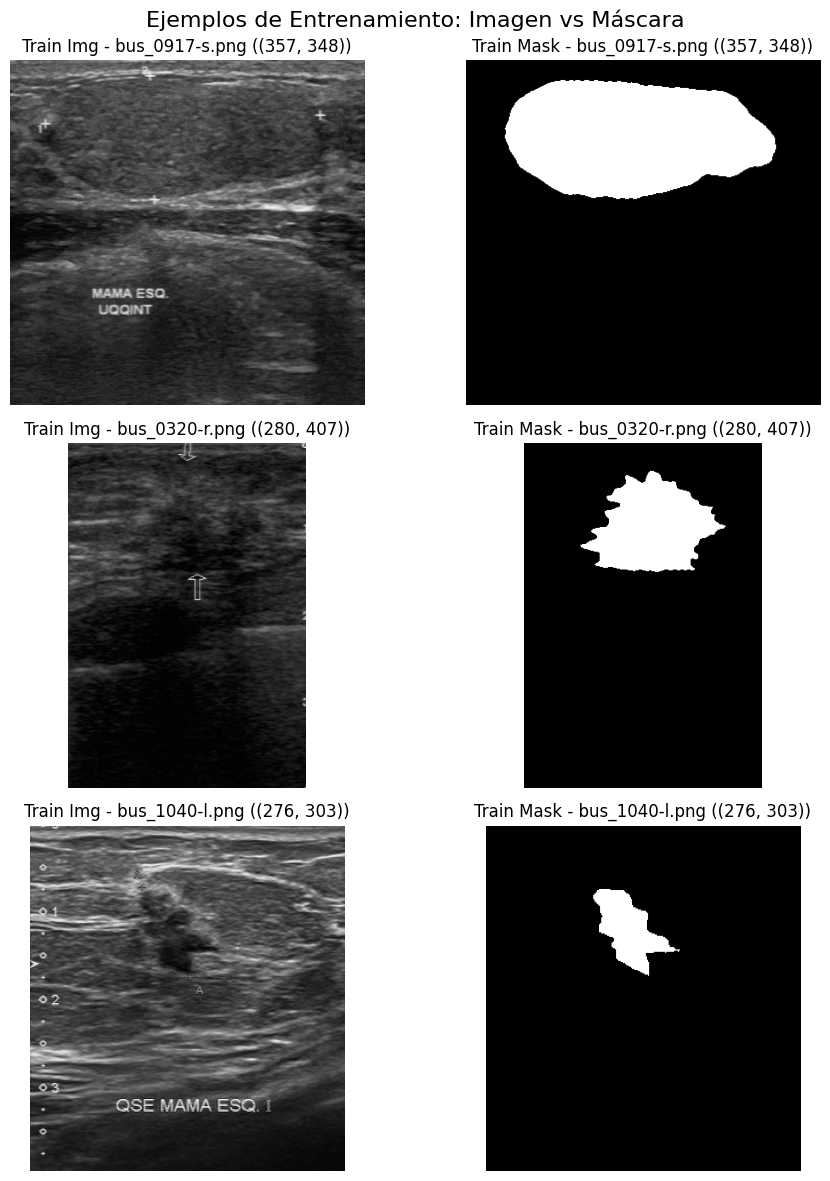

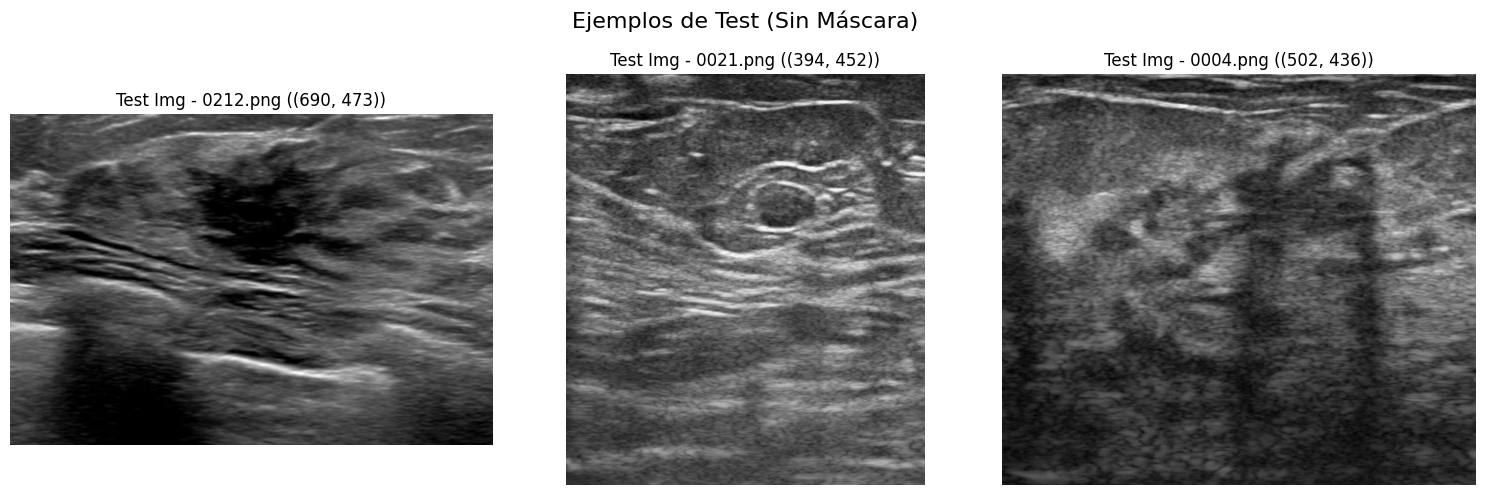

In [ ]:
import random
from PIL import Image
import matplotlib.pyplot as plt

# Seleccionar índices aleatorios
random.seed(SEED)
num_samples = 3
train_indices = random.sample(range(len(train_images)), num_samples)
test_indices = random.sample(range(len(test_images)), num_samples)

# Graficar imágenes de entrenamiento y sus máscaras
fig, axes = plt.subplots(num_samples, 2, figsize=(10, num_samples * 4))
plt.suptitle("Ejemplos de Entrenamiento: Imagen vs Máscara", fontsize=16)
for i, idx in enumerate(train_indices):
    img = Image.open(train_images[idx]).convert("L")
    mask = Image.open(train_masks[idx]).convert("L")

    axes[i, 0].imshow(img, cmap="gray")
    axes[i, 0].set_title(f"Train Img - {Path(train_images[idx]).name} ({img.size})")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title(f"Train Mask - {Path(train_masks[idx]).name} ({mask.size})")
    axes[i, 1].axis("off")
plt.tight_layout()
plt.show()

# Graficar imágenes de test
fig, axes = plt.subplots(1, num_samples, figsize=(15, 5))
plt.suptitle("Ejemplos de Test (Sin Máscara)", fontsize=16)
for i, idx in enumerate(test_indices):
    img = Image.open(test_images[idx]).convert("L")
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(f"Test Img - {Path(test_images[idx]).name} ({img.size})")
    axes[i].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
def analyze_resolutions(image_paths, dataset_name):
    widths = []
    heights = []

    for path in image_paths:
        with Image.open(path) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)

    widths = np.array(widths)
    heights = np.array(heights)

    print(f"=== Análisis de Resoluciones: {dataset_name} ===")
    print(f"Total de imágenes: {len(image_paths)}")
    print(f"Ancho (Width):  Min={widths.min()}, Max={widths.max()}, Promedio={widths.mean():.1f}, Mediana={np.median(widths)}")
    print(f"Alto (Height):  Min={heights.min()}, Max={heights.max()}, Promedio={heights.mean():.1f}, Mediana={np.median(heights)}")

    # Mostrar las 5 resoluciones más comunes
    resolutions = [f"{w}x{h}" for w, h in zip(widths, heights)]
    most_common = Counter(resolutions).most_common(5)
    print("Resoluciones más comunes:")
    for res, count in most_common:
        print(f"  - {res}: {count} imágenes ({count/len(image_paths)*100:.1f}%)")
    print("\n")

analyze_resolutions(train_images, "Entrenamiento (Train)")
analyze_resolutions(test_images, "Prueba (Test)")

=== Análisis de Resoluciones: Entrenamiento (Train) ===
Total de imágenes: 1875
Ancho (Width):  Min=240, Max=579, Promedio=321.3, Mediana=286.0
Alto (Height):  Min=268, Max=478, Promedio=391.3, Mediana=383.0
Resoluciones más comunes:
  - 276x305: 29 imágenes (1.5%)
  - 276x304: 26 imágenes (1.4%)
  - 276x369: 21 imágenes (1.1%)
  - 322x434: 20 imágenes (1.1%)
  - 323x433: 20 imágenes (1.1%)


=== Análisis de Resoluciones: Prueba (Test) ===
Total de imágenes: 252
Ancho (Width):  Min=353, Max=967, Promedio=558.0, Mediana=494.5
Alto (Height):  Min=251, Max=609, Promedio=473.4, Mediana=471.5
Resoluciones más comunes:
  - 423x450: 1 imágenes (0.4%)
  - 666x492: 1 imágenes (0.4%)
  - 436x510: 1 imágenes (0.4%)
  - 566x444: 1 imágenes (0.4%)
  - 502x436: 1 imágenes (0.4%)




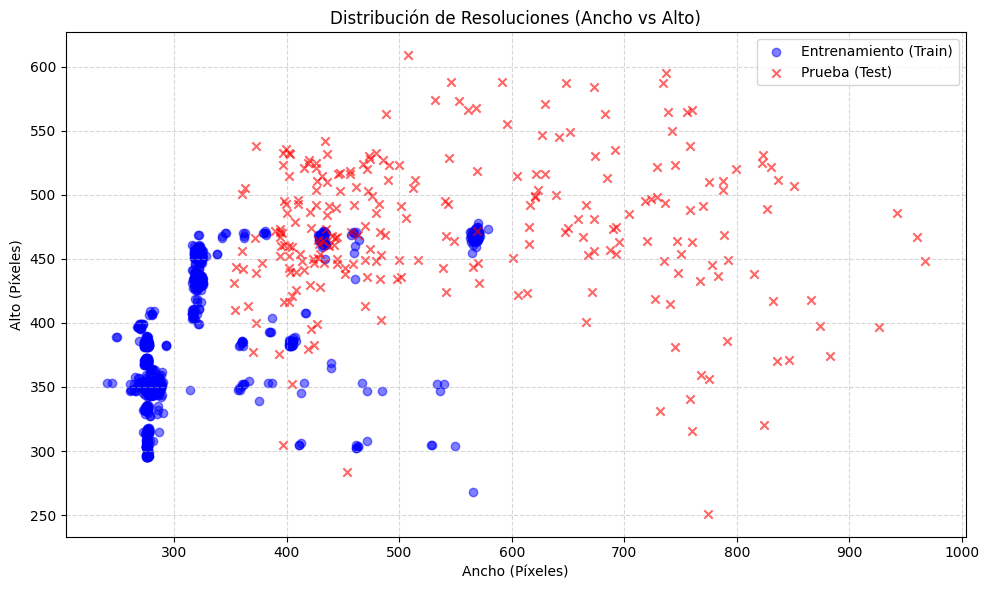

In [ ]:
def get_dimensions(image_paths):
    widths = []
    heights = []
    for path in image_paths:
        with Image.open(path) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
    return widths, heights

# Obtener dimensiones
train_w, train_h = get_dimensions(train_images)
test_w, test_h = get_dimensions(test_images)

# Crear el gráfico
plt.figure(figsize=(10, 6))
plt.scatter(train_w, train_h, alpha=0.5, label='Entrenamiento (Train)', color='blue')
plt.scatter(test_w, test_h, alpha=0.6, label='Prueba (Test)', color='red', marker='x')

plt.title('Distribución de Resoluciones (Ancho vs Alto)')
plt.xlabel('Ancho (Píxeles)')
plt.ylabel('Alto (Píxeles)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## 2. Metadatos del dataset

A partir de las rutas ya cargadas arriba (`train_images`, `train_masks`, `test_images`), se lee `train/train.csv` (`case` = paciente, `device` = equipo de adquisición, `pathology`) y se arma una tabla `df` con una fila por imagen de entrenamiento, que usan el EDA, la partición y el análisis por equipo.

In [ ]:
TRAIN_DIR = BASE_PATH / "train"
df = pd.read_csv(TRAIN_DIR / "train.csv")
sub = pd.read_csv(next(BASE_PATH.rglob("sample_submission.csv")))

# la columna que identifica la imagen es la que no es case / device / pathology
ID_COL = next(c for c in df.columns if c not in ("case", "device", "pathology"))
df["stem"] = df[ID_COL].astype(str).map(lambda s: Path(s).stem)

img_files = {Path(p).stem: p for p in train_images}
mask_files = {Path(p).stem: p for p in train_masks}
df["img_path"] = df["stem"].map(img_files)
df["mask_path"] = df["stem"].map(mask_files)
assert df["img_path"].notna().all() and df["mask_path"].notna().all(), "faltan imágenes o máscaras"

if DEBUG:   # subconjunto chico solo para probar el notebook
    df = df.sample(240, random_state=SEED).reset_index(drop=True)

print(f"Train: {len(df)} imágenes | Test: {len(sub)} imágenes (sin máscara)")
df.head()

Train: 1875 imágenes | Test: 252 imágenes (sin máscara)


,id,case,device,pathology,stem,img_path,mask_path
0,bus_0001-l.png,1,GE Logiq 7 @10-14MHz,malignant,bus_0001-l,/content/train/images/bus_0001-l.png,/content/train/masks/bus_0001-l.png
1,bus_0001-r.png,1,GE Logiq 7 @10-14MHz,malignant,bus_0001-r,/content/train/images/bus_0001-r.png,/content/train/masks/bus_0001-r.png
2,bus_0002-l.png,2,GE Logiq 7 @10-14MHz,benign,bus_0002-l,/content/train/images/bus_0002-l.png,/content/train/masks/bus_0002-l.png
3,bus_0002-r.png,2,GE Logiq 7 @10-14MHz,benign,bus_0002-r,/content/train/images/bus_0002-r.png,/content/train/masks/bus_0002-r.png
4,bus_0003-l.png,3,GE Logiq 7 @10-14MHz,malignant,bus_0003-l,/content/train/images/bus_0003-l.png,/content/train/masks/bus_0003-l.png


## 3. Análisis exploratorio de datos

_Composición del dataset, tamaños, proporción de lesión y comparación entre equipos de adquisición._

El EDA busca responder:

1. cuántos pacientes, equipos y patologías hay, y si hay desbalance
2. qué tamaño tienen las imágenes y cuánto ocupa la lesión
3. en qué se diferencian los equipos (brillo, contraste, resolución), porque el test viene de otros equipos

### 3.1 Composición: pacientes, equipos y patologías

**1875 imágenes de 1064 pacientes** (≈1.76 imágenes por paciente).

pathology,benign,malignant,All
device,,,
GE Logiq 5 @10-12MHz,566,243,809
GE Logiq 7 @10-14MHz,617,285,902
Toshiba Aplio 300 @12-14 MHz,71,68,139
U-Systems @10-14MHz,14,11,25
All,1268,607,1875


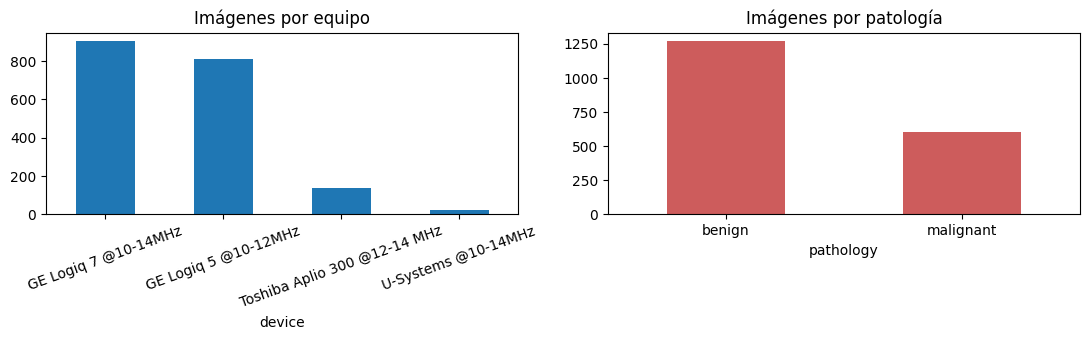

In [ ]:
n_cases = df["case"].nunique()
display(Markdown(f"**{len(df)} imágenes de {n_cases} pacientes** (≈{len(df) / n_cases:.2f} imágenes por paciente)."))

display(pd.crosstab(df["device"], df["pathology"], margins=True))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df["device"].value_counts().plot(kind="bar", ax=axes[0], title="Imágenes por equipo", rot=20)
df["pathology"].value_counts().plot(kind="bar", ax=axes[1], title="Imágenes por patología", rot=0, color="indianred")
plt.tight_layout()
plt.show()

### 3.2 Tamaños, proporción de lesión y brillo

Se recorren todas las imágenes una vez para medir resolución original, fracción de píxeles de lesión y brillo/contraste.

Ancho: 240-579 px (mediana 286) | Alto: 268-478 px (mediana 383)
Lesión: mediana 6.2% de la imagen (p5 = 1.5%, p95 = 22.5%)


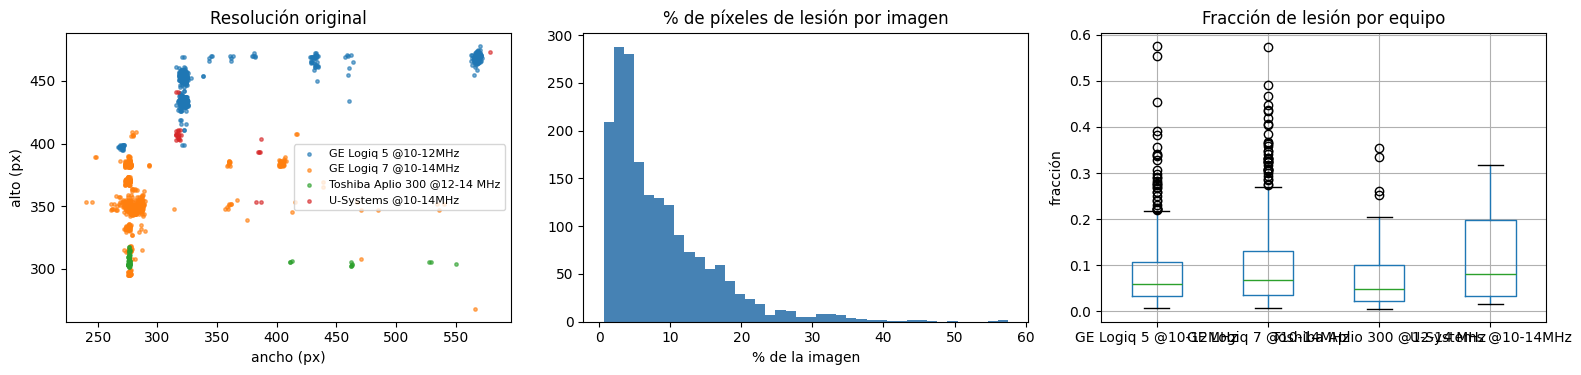

In [ ]:
rows = []
for ip, mp in zip(df["img_path"], df["mask_path"]):
    with Image.open(ip) as im:
        w, h = im.size
        a = np.array(im.convert("L"), dtype=np.float32)
    with Image.open(mp) as mm:
        m = np.array(mm.convert("L")) > 127
    rows.append((w, h, m.mean(), a.mean(), a.std()))

stat_cols = ["width", "height", "lesion_frac", "mean_int", "std_int"]
df[stat_cols] = pd.DataFrame(rows, columns=stat_cols, index=df.index)

print(f"Ancho: {df.width.min():.0f}-{df.width.max():.0f} px (mediana {df.width.median():.0f}) | "
      f"Alto: {df.height.min():.0f}-{df.height.max():.0f} px (mediana {df.height.median():.0f})")
print(f"Lesión: mediana {100 * df.lesion_frac.median():.1f}% de la imagen "
      f"(p5 = {100 * df.lesion_frac.quantile(.05):.1f}%, p95 = {100 * df.lesion_frac.quantile(.95):.1f}%)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for dev, g in df.groupby("device"):
    axes[0].scatter(g.width, g.height, s=6, label=dev, alpha=.6)
axes[0].set(title="Resolución original", xlabel="ancho (px)", ylabel="alto (px)")
axes[0].legend(fontsize=8)
axes[1].hist(100 * df.lesion_frac, bins=40, color="steelblue")
axes[1].set(title="% de píxeles de lesión por imagen", xlabel="% de la imagen")
df.boxplot(column="lesion_frac", by="device", ax=axes[2])
axes[2].set(title="Fracción de lesión por equipo", xlabel="", ylabel="fracción")
plt.suptitle("")
plt.tight_layout()
plt.show()

### 3.3 Comparación entre equipos de adquisición

,imagenes,pacientes,ancho_mediano,alto_mediano,lesion_pct_mediana,brillo_medio,contraste_medio
device,,,,,,,
GE Logiq 5 @10-12MHz,809,490,323.0,448.0,5.9,104.599998,49.799999
GE Logiq 7 @10-14MHz,902,488,276.0,352.0,6.7,66.900002,30.700001
Toshiba Aplio 300 @12-14 MHz,139,72,276.0,305.0,4.8,72.000000,39.099998
U-Systems @10-14MHz,25,14,317.0,407.0,8.1,35.299999,34.799999


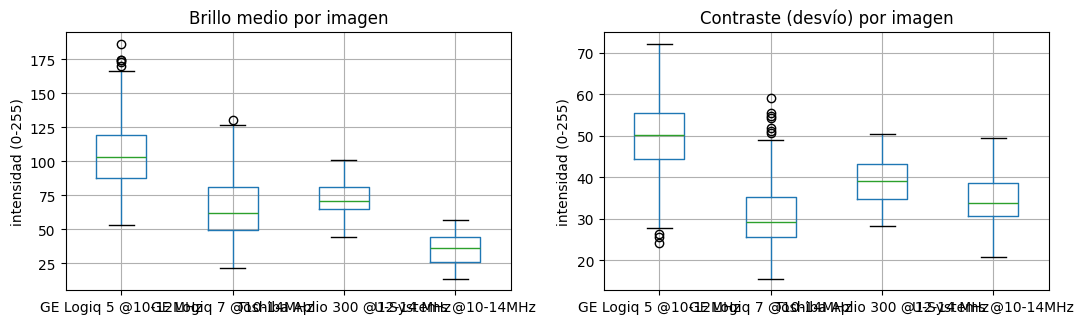

In [ ]:
dev_table = df.groupby("device").agg(
    imagenes=("stem", "size"),
    pacientes=("case", "nunique"),
    ancho_mediano=("width", "median"),
    alto_mediano=("height", "median"),
    lesion_pct_mediana=("lesion_frac", lambda s: 100 * s.median()),
    brillo_medio=("mean_int", "mean"),
    contraste_medio=("std_int", "mean"),
)
display(dev_table.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df.boxplot(column="mean_int", by="device", ax=axes[0])
axes[0].set(title="Brillo medio por imagen", xlabel="", ylabel="intensidad (0-255)")
df.boxplot(column="std_int", by="device", ax=axes[1])
axes[1].set(title="Contraste (desvío) por imagen", xlabel="", ylabel="intensidad (0-255)")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 4. Preprocesamiento y partición train / validación

_Partición por paciente, tamaño de entrada, normalización, augmentation y `Dataset`._

### 4.1 Partición

**Por paciente (`case`)**, no por imagen: un paciente tiene varias vistas de la misma lesión (`-l`, `-r`), y si estuvieran repartidas entre train y validación el modelo vería "la misma imagen" en ambos y la validación sería optimista. Además se **estratifica por equipo** para que cada equipo esté representado en validación en la misma proporción que en train (`StratifiedGroupKFold`, 7 pliegues, usamos 1 de ellos ≈ 14% para validación).

El test de Kaggle no participa: la validación es la única referencia propia.

In [ ]:
def split_cases(idx, n_splits=7):
    """Parte los índices `idx` de df en (train, val), sin compartir pacientes y estratificando por equipo."""
    s = df.iloc[idx]
    a, b = next(StratifiedGroupKFold(n_splits, shuffle=True, random_state=SEED).split(s, s["device"], s["case"]))
    return idx[a], idx[b]


tr_idx, va_idx = split_cases(np.arange(len(df)))

assert set(df.iloc[tr_idx]["case"]).isdisjoint(df.iloc[va_idx]["case"]), "hay pacientes en train y val"
print(f"Train: {len(tr_idx)} imágenes | Val: {len(va_idx)} imágenes")
pd.DataFrame({"train": df.iloc[tr_idx]["device"].value_counts(normalize=True),
              "val": df.iloc[va_idx]["device"].value_counts(normalize=True)}).round(3)

Train: 1605 imágenes | Val: 270 imágenes


,train,val
device,,
GE Logiq 7 @10-14MHz,0.480,0.485
GE Logiq 5 @10-12MHz,0.431,0.437
Toshiba Aplio 300 @12-14 MHz,0.075,0.067
U-Systems @10-14MHz,0.014,0.011


### 4.2 Tamaño de entrada y carga en memoria

Las imágenes se llevan a **320×320** en escala de grises (1 canal). Es un compromiso: conserva el detalle del borde de la lesión, es divisible por 2⁴ (4 reducciones con max-pool) y permite entrenar varias corridas en tiempo razonable. Las máscaras se redimensionan con interpolación *nearest* y se binarizan, para que sigan siendo 0/1. Al predecir en test se vuelve al tamaño original de cada imagen.

Todo el dataset cabe en memoria (del orden de 100 MB en uint8 a 320×320), así que se carga una vez y el `Dataset` solo aplica las transformaciones.

In [ ]:
IMG_SIZE = 128 if DEBUG else 320


def read_resized(path, resample):
    with Image.open(path) as im:
        return torch.from_numpy(np.array(im.convert("L").resize((IMG_SIZE, IMG_SIZE), resample)))


X = torch.stack([read_resized(p, Image.BILINEAR) for p in df["img_path"]]).unsqueeze(1)                 # (N, 1, H, W) uint8
Y = (torch.stack([read_resized(p, Image.NEAREST) for p in df["mask_path"]]).unsqueeze(1) > 127).to(torch.uint8)  # 0 / 1
print(f"X {tuple(X.shape)} {X.dtype} | Y {tuple(Y.shape)} {Y.dtype} | píxeles de lesión: {Y.float().mean():.1%}")

X (1875, 1, 320, 320) torch.uint8 | Y (1875, 1, 320, 320) torch.uint8 | píxeles de lesión: 8.7%


### 4.3 Transformaciones

**Validación (y test):** pasar a float en [0, 1] y normalizar con la media y el desvío del conjunto de entrenamiento (una sola media y un solo desvío, porque hay un canal).

**Train con augmentation**, igual que en la Tarea 1, antes de pasar a float:

- `RandomResizedCrop(scale=(0.7, 1.0))`: simula distintos encuadres y tamaños de lesión.
- `RandomHorizontalFlip(0.5)`: una lesión espejada sigue siendo una lesión.
- `RandomRotation(10)`: simula una leve inclinación del transductor.

**No se usan deformaciones elásticas** (decisión del grupo, a diferencia del paper). Con `torchvision.transforms.v2`, si se pasa la imagen como `tv_tensors.Image` y la máscara como `tv_tensors.Mask`, las transformaciones geométricas se aplican con **los mismos parámetros aleatorios a ambas**; la máscara se interpola con *nearest* y la normalización solo afecta a la imagen.

In [ ]:
normalize = [T.ToDtype(torch.float32, scale=True), T.Normalize(mean=[0.5], std=[0.5])]

# Validación y test: sin augmentation
eval_transforms = T.Compose(normalize)

# Train con todas las transformaciones (geométricas + contraste)
train_transforms_aug = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=15, interpolation=InterpolationMode.BILINEAR),
    T.ColorJitter(contrast=0.4),                 # Variación de contraste para simular otros equipos
    T.RandomAutocontrast(p=0.5),                 # Contraste automático aleatorio
    *normalize,     # pasar a float [0, 1] y normalizar, igual que en validación
])

### 4.4 `BUSDataset`

Guarda las imágenes y máscaras ya en memoria y aplica el transform en cada `__getitem__`, de modo que el augmentation cambia cada vez que se pide una muestra. Devuelve la imagen `(1, H, W)` y la máscara `(1, H, W)` en float.

In [ ]:
class BUSDataset(Dataset):
    def __init__(self, X, Y, transform):
        self.X, self.Y, self.transform = X, Y, transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        img, mask = self.transform(tv_tensors.Image(self.X[i]), tv_tensors.Mask(self.Y[i]))
        return img.as_subclass(torch.Tensor), mask.as_subclass(torch.Tensor).float()

ds_aug = BUSDataset(X, Y, train_transforms_aug)
ds_eval = BUSDataset(X, Y, eval_transforms)

### 4.5 Verificación visual del data augmentation

Una imagen de train con su máscara: la primera es la versión sin augmentation y las siguientes son versiones aleatorias. La máscara tiene que seguir a la lesión en todas.

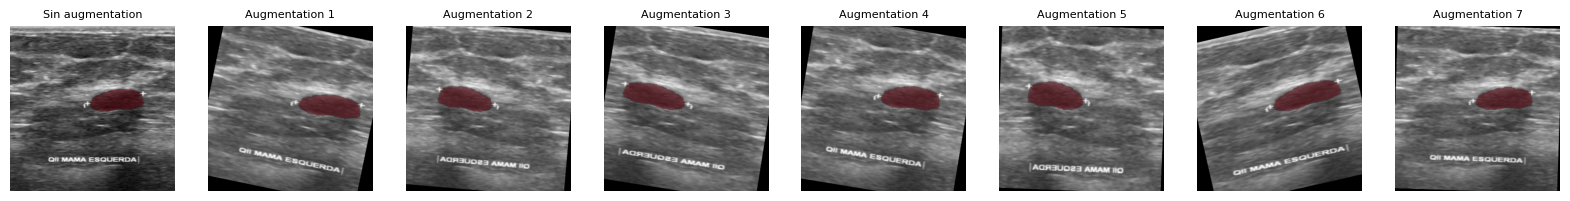

In [ ]:
# Definimos las constantes de normalización que se quitaron de la celda c037
MEAN = 0.5
STD = 0.5

def denorm(t):
    return (t * STD + MEAN).clamp(0, 1).squeeze().numpy()

def show_overlay(ax, img, mask, title=None):
    ax.imshow(img, cmap="gray")
    ax.imshow(np.ma.masked_equal((np.asarray(mask) > 0).astype(np.uint8), 0), cmap="Reds", alpha=0.45, vmin=0, vmax=1)
    ax.set_title(title, fontsize=8)
    ax.axis("off")

demo = int(tr_idx[0])
pairs = [ds_eval[demo]] + [ds_aug[demo] for _ in range(7)]
fig, axes = plt.subplots(1, 8, figsize=(20, 3))
for k, (ax, (img, mask)) in enumerate(zip(axes, pairs)):
    show_overlay(ax, denorm(img), mask.squeeze().numpy(), "Sin augmentation" if k == 0 else f"Augmentation {k}")
plt.show()

### 4.6 DataLoaders

`get_loaders(tr, va)` arma los loaders para una partición dada:

- `train_aug` / `train_noaug`: las mismas imágenes de train con y sin augmentation.
- `train_eval`: submuestra fija de 300 imágenes de train sin augmentation, solo para medir el *Dice de train* en cada época.
- `val`: validación sin augmentation (no se mezcla, así que el orden coincide con `va_idx`).

In [ ]:
BATCH_SIZE = 16   # se redefine el BATCH_SIZE de la parte inicial (64): una U-Net a 256×256 con 64 imágenes por batch ocupa demasiada memoria de GPU


def make_loader(ds, idx, shuffle=False):
    return DataLoader(Subset(ds, list(idx)), batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS)


def get_loaders(tr, va):
    sample = np.random.RandomState(SEED).choice(tr, min(300, len(tr)), replace=False)
    return {"train_aug": make_loader(ds_aug, tr, True), "train_noaug": make_loader(ds_eval, tr, True),
            "train_eval": make_loader(ds_eval, sample), "val": make_loader(ds_eval, va)}


loaders = get_loaders(tr_idx, va_idx)
x_b, y_b = next(iter(loaders["train_aug"]))
print(f"Batch de train: x {tuple(x_b.shape)} {x_b.dtype} | y {tuple(y_b.shape)} {y_b.dtype} | valores de y: {y_b.unique().tolist()}")

for k in ("train_aug", "train_noaug", "val"):   # todas las corridas deben recibir float32 normalizado en [-1, 1] y máscaras 0/1
    xb, yb = next(iter(loaders[k]))
    assert xb.dtype == torch.float32 and xb.min() >= -1.001 and xb.max() <= 1.001, f"{k}: entrada mal normalizada ({xb.dtype}, {xb.min():.1f} a {xb.max():.1f})"
    assert set(yb.unique().tolist()) <= {0.0, 1.0}, f"{k}: la máscara no es binaria"
print("Entradas verificadas (train con y sin augmentation, y validación): float32 en [-1, 1] y máscaras 0/1")

Batch de train: x (16, 1, 320, 320) torch.float32 | y (16, 1, 320, 320) torch.float32 | valores de y: [0.0, 1.0]
Entradas verificadas (train con y sin augmentation, y validación): float32 en [-1, 1] y máscaras 0/1


## 5. Modelo

_U-Net desde cero, modular._

Se respeta la estructura del paper: un **camino de contracción** de `depth` bloques con max-pool 2×2 que duplican los canales, un **cuello de botella**, y un **camino de expansión** con convoluciones transpuestas 2×2 que reducen los canales a la mitad, concatenan la *skip connection* del nivel correspondiente y aplican otro bloque. Una convolución 1×1 final da un logit por píxel. Cada bloque son dos `Conv 3×3 → BatchNorm → ReLU`.

**Modularidad:** `conv_block` es el único bloque y `UNet` construye todos los niveles con listas (`ModuleList`), a partir de la lista de canales `base · 2^i`. Con `base=64, depth=4` es exactamente la U-Net del paper (1024 canales en el fondo); cambiar `base` o `depth` ajusta el tamaño del modelo sin tocar el código.

**Decisiones:**

- `padding=1`: la salida tiene el mismo tamaño que la entrada y los mapas de skip se concatenan sin recortarlos (el paper usa convoluciones sin padding y la estrategia *overlap-tile*).
- `BatchNorm` opcional (`use_bn`), mejora aceptada por el enunciado.
- `Dropout2d` en el cuello de botella, como el paper (*"drop-out layers at the end of the contracting path"*); con `dropout=0` queda desactivado.
- Inicialización de pesos Kaiming normal (desvío √(2/N)), la que propone el paper.
- `base=32` por defecto: con pocas imágenes de entrenamiento y entrenando desde cero, un modelo de ≈7.8M parámetros alcanza y entrena bastante más rápido que el de 64 filtros base (≈31M). Para replicar el paper alcanza con `BASE = 64`.
- La salida son **logits** (1 canal); la sigmoide está incluida en la pérdida.

In [ ]:
def conv_block(cin, cout, use_bn=True):
    layers = []
    for c in (cin, cout):  # dos convoluciones: cin->cout y cout->cout
        layers += [nn.Conv2d(c, cout, 3, padding=1, bias=not use_bn),
                   nn.BatchNorm2d(cout) if use_bn else nn.Identity(),
                   nn.ReLU(inplace=True)]
    return nn.Sequential(*layers)


class UNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, base=32, depth=4, use_bn=True, dropout=0.0):
        super().__init__()
        ch = [base * 2 ** i for i in range(depth + 1)]                       # p.ej. 32, 64, 128, 256, 512
        self.enc = nn.ModuleList([conv_block(i, o, use_bn) for i, o in zip([in_ch] + ch[:-1], ch)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in range(depth)])
        self.dec = nn.ModuleList([conv_block(2 * ch[i], ch[i], use_bn) for i in range(depth)])
        self.pool, self.drop = nn.MaxPool2d(2), nn.Dropout2d(dropout)
        self.head = nn.Conv2d(ch[0], out_ch, 1)
        self.apply(self._init)

    @staticmethod
    def _init(m):  # Kaiming normal: desvío sqrt(2/N), como en el paper
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, x):
        skips = []
        for block in self.enc[:-1]:                                          # contracción
            x = block(x)
            skips.append(x)
            x = self.pool(x)
        x = self.drop(self.enc[-1](x))                                       # cuello de botella
        for up, block, skip in zip(reversed(self.up), reversed(self.dec), reversed(skips)):  # expansión
            x = block(torch.cat([skip, up(x)], dim=1))
        return self.head(x)


BASE = 16 if DEBUG else 32
summary(UNet(base=BASE), input_size=(BATCH_SIZE, 1, IMG_SIZE, IMG_SIZE))

Layer (type:depth-idx)                   Output Shape              Param #
UNet                                     [16, 1, 320, 320]         --
├─ModuleList: 1-9                        --                        (recursive)
│    └─Sequential: 2-1                   [16, 32, 320, 320]        --
│    │    └─Conv2d: 3-1                  [16, 32, 320, 320]        288
│    │    └─BatchNorm2d: 3-2             [16, 32, 320, 320]        64
│    │    └─ReLU: 3-3                    [16, 32, 320, 320]        --
│    │    └─Conv2d: 3-4                  [16, 32, 320, 320]        9,216
│    │    └─BatchNorm2d: 3-5             [16, 32, 320, 320]        64
│    │    └─ReLU: 3-6                    [16, 32, 320, 320]        --
├─MaxPool2d: 1-2                         [16, 32, 160, 160]        --
├─ModuleList: 1-9                        --                        (recursive)
│    └─Sequential: 2-2                   [16, 64, 160, 160]        --
│    │    └─Conv2d: 3-7                  [16, 64, 160, 160]    

### 5.1 Función de pérdida: BCE + Dice

- **BCE** (`binary_cross_entropy_with_logits`) da gradientes estables píxel a píxel, pero como la lesión ocupa una fracción chica de la imagen, el modelo puede "ganar" prediciendo casi todo fondo.
- **Dice loss** = 1 − Dice (calculado por imagen y promediado) optimiza directamente la métrica de la competencia y es insensible al desbalance fondo/lesión.

La pérdida es `BCE + dice_weight · DiceLoss`. Con `dice_weight=0` es BCE sola, lo que permite compararlas en los experimentos.

**BCE ponderada en los bordes (opcional, `edge_w0 > 0`).** El paper pondera más los píxeles cercanos a los bordes. Versión simplificada para una lesión por imagen: los píxeles a menos de `edge_r` píxeles del contorno manual (dentro o fuera) pesan `1 + edge_w0` y el resto pesa 1. La banda se obtiene dentro de la pérdida como dilatación − erosión de la máscara (`max_pool2d`), así coincide siempre con la imagen aumentada. La BCE se promedia con esos pesos para conservar la escala. El término Dice no se pondera.

### 5.2 Métrica: Dice por imagen

Igual que Kaggle: Dice de cada imagen con la predicción binarizada en 0.5 y luego promedio sobre las imágenes.

In [ ]:
class BCEDiceLoss(nn.Module):
    def __init__(self, dice_weight=1.0, smooth=1.0, edge_w0=0.0, edge_r=4):
        super().__init__()
        self.w, self.s, self.w0, self.r = dice_weight, smooth, edge_w0, edge_r

    def forward(self, logits, y):
        bce = F.binary_cross_entropy_with_logits(logits, y, reduction="none")
        if self.w0 > 0:  # banda de ±edge_r px alrededor del contorno: dilatación - erosión de la máscara
            k = 2 * self.r + 1
            band = F.max_pool2d(y, k, 1, self.r) + F.max_pool2d(-y, k, 1, self.r)
            wmap = 1 + self.w0 * band
            bce = (bce * wmap).sum() / wmap.sum()
        else:
            bce = bce.mean()
        loss = bce
        if self.w > 0:
            p = torch.sigmoid(logits)
            inter, den = (p * y).sum((1, 2, 3)), p.sum((1, 2, 3)) + y.sum((1, 2, 3))
            loss = loss + self.w * (1 - (2 * inter + self.s) / (den + self.s)).mean()
        return loss


@torch.no_grad()
def predict_probs(model, loader):
    """Probabilidades (N, 1, H, W) en CPU, en el orden del loader."""
    model.eval()
    return torch.cat([torch.sigmoid(model(x.to(DEVICE))).cpu() for x, _ in loader])


@torch.no_grad()
def dice_per_image(model, loader, thr=0.5):
    """Dice de cada imagen del loader (array numpy, en el orden del loader)."""
    model.eval()
    out = []
    for x, y in loader:
        p = (torch.sigmoid(model(x.to(DEVICE))) > thr).float().cpu()
        inter, den = (p * y).sum((1, 2, 3)), p.sum((1, 2, 3)) + y.sum((1, 2, 3))
        out.append(2 * inter / den.clamp(min=1))
    return torch.cat(out).numpy()

## 6. Entrenamiento y experimentos

_Loop de entrenamiento, logging en wandb y experimentos encadenados._

Se entrena con `utils.train`, optimizador **AdamW** (con `weight_decay=0` equivale a Adam), `lr=1e-3` y **early stopping** sobre la loss de validación (paciencia de 8 épocas, hasta 40 épocas). Al terminar, el modelo queda con los pesos de la mejor época. En cada época se registra además el Dice de train y de validación.

Como en la Tarea 1, los experimentos son **encadenados**: parten de un baseline y cada uno cambia **una sola cosa** respecto al anterior.

| Experimento | Augmentation | Pérdida | Weight decay | Dropout |
|---|---|---|---|---|
| 1 `exp1_bce_sin_aug` (baseline) | no | BCE | 0 | 0 |
| 2 `exp2_bce_aug` | sí | BCE | 0 | 0 |
| 3 `exp3_bcedice_aug` | sí | **BCE + Dice** | 0 | 0 |
| 4 `exp4_bcedice_aug_wd` | sí | BCE + Dice | **1e-4** | 0 |
| 5 `exp5_bcedice_aug_wd_do` | sí | BCE + Dice | 1e-4 | **0.2** |
| 6 `exp6_bcedice_aug_bordes` (parte del 3) | sí | BCE **ponderada en bordes** + Dice | 0 | 0 |

El experimento 6 **parte del 3** y cambia una sola cosa: la ponderación de bordes en la BCE (sección 6.5).

**Criterio de elección:** como la pérdida cambia entre experimentos, las `val_loss` no son comparables entre sí. El modelo final se elige por el **Dice de validación**, que es la métrica de la competencia.

In [ ]:
LR = 1e-3
EPOCHS = 2 if DEBUG else 50
PATIENCE = 10
WEIGHT_DECAY = 1e-4
DROPOUT = 0.2
EDGE_W0, EDGE_R = 5.0, 4      # bordes: peso extra 5 en una banda de ±4 px alrededor del contorno

EXPERIMENTS = {
    "exp1_bce_sin_aug":        dict(use_aug=False, dice_weight=0.0, weight_decay=0.0,          dropout=0.0),
    "exp2_bce_aug":            dict(use_aug=True,  dice_weight=0.0, weight_decay=0.0,          dropout=0.0),
    "exp3_bcedice_aug":        dict(use_aug=True,  dice_weight=1.0, weight_decay=0.0,          dropout=0.0),
    "exp4_bcedice_aug_wd":     dict(use_aug=True,  dice_weight=1.0, weight_decay=WEIGHT_DECAY, dropout=0.0),
    "exp5_bcedice_aug_wd_do":  dict(use_aug=True,  dice_weight=1.0, weight_decay=WEIGHT_DECAY, dropout=DROPOUT),
    "exp6_bcedice_aug_bordes": dict(use_aug=True,  dice_weight=1.0, weight_decay=0.0,          dropout=0.0, edge_w0=EDGE_W0, edge_r=EDGE_R),
}

### 6.1 `run_experiment` y gráficos

`run_experiment` crea el modelo, abre una corrida de wandb, entrena con `utils.train` (usando `log_fn` para registrar el Dice en cada época), calcula el Dice final de validación con los mejores pesos y devuelve el modelo, las curvas y las métricas.

In [ ]:
class Progress:
    """Envuelve un DataLoader e imprime el avance dentro de cada época (así se ve que el entrenamiento no está trabado)."""

    def __init__(self, loader):
        self.loader = loader

    def __len__(self):
        return len(self.loader)

    def __iter__(self):
        for i, batch in enumerate(self.loader):
            if i % 10 == 0:
                print(f"    entrenando... batch {i}/{len(self.loader)}", end="\r")
            yield batch
        print(" " * 50, end="\r")


def run_experiment(name, ld, *, use_aug, dice_weight, weight_decay, dropout, edge_w0=0.0, edge_r=4, base=BASE, lr=LR, epochs=EPOCHS, patience=PATIENCE):
    set_seed(SEED)
    model = UNet(base=base, dropout=dropout).to(DEVICE)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = BCEDiceLoss(dice_weight, edge_w0=edge_w0, edge_r=edge_r)

    config = {"architecture": "UNet", "base_filters": base, "img_size": IMG_SIZE, "augmentation": use_aug,
              "dice_weight": dice_weight, "edge_w0": edge_w0, "edge_r": edge_r, "weight_decay": weight_decay, "dropout": dropout, "optimizer": "AdamW",
              "lr": lr, "batch_size": BATCH_SIZE, "max_epochs": epochs, "patience": patience, "seed": SEED,
              "hardware": HARDWARE, "n_params": sum(p.numel() for p in model.parameters())}
    run = wandb_safe(lambda: wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY, name=name, config=config, mode=WANDB_MODE))

    hist = {"train_dice": [], "val_dice": []}

    def log_fn(epoch, train_loss, val_loss):  # utils.train la llama al final de cada época
        td = dice_per_image(model, ld["train_eval"]).mean()
        vd = dice_per_image(model, ld["val"]).mean()
        hist["train_dice"].append(td)
        hist["val_dice"].append(vd)
        if run is not None:
            wandb_safe(lambda: wandb.log({"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss, "train_dice": float(td), "val_dice": float(vd)}))
        print(f"  Época {epoch + 1:03d} | loss {train_loss:.4f} / {val_loss:.4f} | Dice {td:.4f} / {vd:.4f}  (train / val)")

    t0 = time.time()
    train_losses, val_losses = train(model, optimizer, criterion, Progress(ld["train_aug" if use_aug else "train_noaug"]), ld["val"],
                                     DEVICE, patience=patience, epochs=epochs, log_fn=log_fn)
    train_time = time.time() - t0

    best_epoch = int(np.argmin(val_losses)) + 1         # utils.train restaura los pesos de esta época
    val_dice = float(dice_per_image(model, ld["val"]).mean())
    if run is not None:
        wandb_safe(lambda: wandb.summary.update({"best_epoch": best_epoch, "val_dice": val_dice, "train_time_sec": train_time}))
        wandb_safe(wandb.finish)
    print(f"{name}: Dice val = {val_dice:.4f} (mejor época {best_epoch} de {len(val_losses)}, {train_time:.0f} s)")

    return {"model": model, "config": config, "train_losses": train_losses, "val_losses": val_losses,
            "train_dices": hist["train_dice"], "val_dices": hist["val_dice"], "val_dice": val_dice,
            "best_epoch": best_epoch, "n_epochs": len(val_losses), "train_time_sec": train_time}


def plot_history(r, name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, (tr, va), ylabel in zip(axes, [(r["train_losses"], r["val_losses"]), (r["train_dices"], r["val_dices"])], ["Loss", "Dice"]):
        ax.plot(range(1, len(tr) + 1), tr, label="train")
        ax.plot(range(1, len(va) + 1), va, label="validación")
        ax.axvline(r["best_epoch"], color="gray", linestyle="--", label=f"mejor época ({r['best_epoch']})")
        ax.set(title=f"{name}: {ylabel}", xlabel="Época", ylabel=ylabel)
        ax.grid(True)
        ax.legend()
    plt.tight_layout()
    plt.show()

### 6.2 Corridas

Se corren los 6 experimentos (la celda **omite los que ya están en `results`**: si ya corriste los primeros, solo entrena el nuevo). Cada uno imprime el progreso por época y muestra sus curvas al terminar (la loss de train se mide con augmentation y la de validación sin él, por lo que no son estrictamente comparables; el Dice de train se mide sin augmentation).

Iniciando el exp6_bcedice_aug_bordes con el pipeline que incluye transformaciones de contraste...
  Época 001 | loss 1.1388 / 1.0596 | Dice 0.3548 / 0.3655  (train / val)
  Época 002 | loss 0.8184 / 0.8394 | Dice 0.5908 / 0.5575  (train / val)
  Época 003 | loss 0.6627 / 0.6128 | Dice 0.7315 / 0.7028  (train / val)
  Época 004 | loss 0.5891 / 0.5826 | Dice 0.7587 / 0.7261  (train / val)
  Época 005 | loss 0.5351 / 0.4497 | Dice 0.8278 / 0.7986  (train / val)
  Época 006 | loss 0.5241 / 0.5139 | Dice 0.7674 / 0.7532  (train / val)
  Época 007 | loss 0.4914 / 0.4177 | Dice 0.8383 / 0.8137  (train / val)
  Época 008 | loss 0.4677 / 0.4145 | Dice 0.8327 / 0.8107  (train / val)
  Época 009 | loss 0.4625 / 0.5230 | Dice 0.7681 / 0.7558  (train / val)
  Época 010 | loss 0.4538 / 0.3961 | Dice 0.8531 / 0.8252  (train / val)
  Época 011 | loss 0.4362 / 0.3848 | Dice 0.8598 / 0.8322  (train / val)
  Época 012 | loss 0.4318 / 0.3441 | Dice 0.8722 / 0.8526  (train / val)
  Época 013 | loss 0.4293 

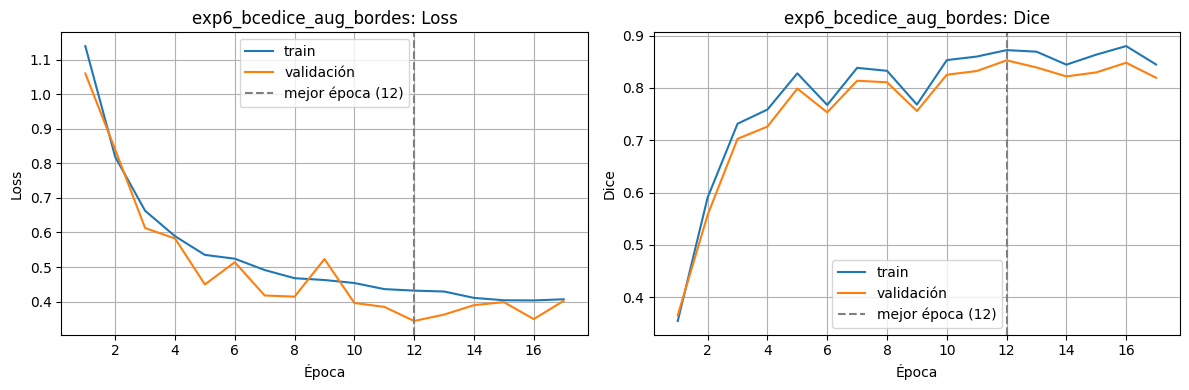

In [ ]:
# Ejecutar específicamente el Experimento 6 usando el pipeline de aumentación actualizado con contraste
name_exp6 = "exp6_bcedice_aug_bordes"
cfg_exp6 = EXPERIMENTS[name_exp6]

print(f"Iniciando el {name_exp6} con el pipeline que incluye transformaciones de contraste...")
results[name_exp6] = run_experiment(name_exp6, loaders, **cfg_exp6)
plot_history(results[name_exp6], name_exp6)

In [ ]:
# Definir rle_encode y predict_mask localmente para evitar el NameError
def rle_encode(mask):
    pixels = np.array(mask).flatten(order="F")              # orden Fortran
    pixels = np.concatenate([[0], pixels, [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1       # transiciones
    runs[1::2] = runs[1::2] - runs[::2]                     # longitudes
    return " ".join(str(x) for x in runs)

@torch.no_grad()
def predict_mask(model, path, thr=0.5):
    model.eval()
    with Image.open(path) as im:
        w, h = im.size
        x = torch.from_numpy(np.array(im.convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)))[None]
    x = eval_transforms(tv_tensors.Image(x)).as_subclass(torch.Tensor)[None].to(DEVICE)
    p = (torch.sigmoid(model(x)) + torch.sigmoid(model(x.flip(-1))).flip(-1)) / 2  # TTA
    p = F.interpolate(p, size=(h, w), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
    mask = p > thr
    if not mask.any():
        mask = p >= 0.5 * p.max()
    return mask.astype(np.uint8)

# Obtener el modelo del Experimento 6
model_exp6 = results["exp6_bcedice_aug_bordes"]["model"]

# Predecir sobre las imágenes de prueba y generar RLE
print("Generando predicciones para el test con el modelo del Experimento 6...")
ids = sub["id"].astype(str).tolist()
test_files = {Path(p).stem: p for p in test_images}
rles_exp6 = [rle_encode(predict_mask(model_exp6, test_files[Path(i).stem])) for i in ids]

# Crear DataFrame de entrega
submission_exp6 = pd.DataFrame({"id": sub["id"], "encoded_pixels": rles_exp6})

# Validar que no haya máscaras vacías
assert len(submission_exp6) == len(sub) and (submission_exp6["encoded_pixels"].str.len() > 0).all(), "Error: hay máscaras vacías"

# Guardar archivos
submission_exp6.to_csv("submission_exp6.csv", index=False)
submission_exp6.to_csv("submission.csv", index=False)  # Sobrescribe el principal para descarga directa
print("¡submission_exp6.csv y submission.csv generados con éxito!")
submission_exp6.head()

Generando predicciones para el test con el modelo del Experimento 6...
¡submission_exp6.csv y submission.csv generados con éxito!


,id,encoded_pixels
0,0000.png,59459 1 59906 6 60356 7 60804 10 61253 13 6170...
1,0001.png,86287 1 86778 2 87272 1 87764 3 88255 4 88747 ...
2,0002.png,62953 4 63458 15 63967 18 64472 1 64474 22 649...
3,0003.png,25167 1 25609 4 25617 1 26050 1 26053 4 26494 ...
4,0004.png,39008 1 39416 5 39441 4 39848 13 39877 9 40282...


In [ ]:
name_exp6_wd = "exp6_bcedice_aug_bordes_wd"
cfg_exp6_wd = {
    "use_aug": True,
    "dice_weight": 1.0,
    "weight_decay": WEIGHT_DECAY,
    "dropout": 0.0,
    "edge_w0": EDGE_W0,
    "edge_r": EDGE_R
}

print(f"Iniciando el {name_exp6_wd} (contraste + bordes + weight decay {WEIGHT_DECAY})...")
results[name_exp6_wd] = run_experiment(name_exp6_wd, loaders, **cfg_exp6_wd)
plot_history(results[name_exp6_wd], name_exp6_wd)

Iniciando el exp6_bcedice_aug_bordes_wd (contraste + bordes + weight decay 0.0001)...
  Época 001 | loss 1.1308 / 0.9577 | Dice 0.4799 / 0.4829  (train / val)
  Época 002 | loss 0.8244 / 0.8381 | Dice 0.5588 / 0.5489  (train / val)
  Época 003 | loss 0.6661 / 0.5596 | Dice 0.7510 / 0.7373  (train / val)
  Época 004 | loss 0.5916 / 0.7275 | Dice 0.6434 / 0.6251  (train / val)
  Época 005 | loss 0.5455 / 0.4471 | Dice 0.8257 / 0.7992  (train / val)
  Época 006 | loss 0.5232 / 0.5137 | Dice 0.7757 / 0.7475  (train / val)
  Época 007 | loss 0.4992 / 0.4473 | Dice 0.8142 / 0.7890  (train / val)
  Época 008 | loss 0.4737 / 0.4495 | Dice 0.8147 / 0.7918  (train / val)


In [ ]:
# Obtener el modelo del nuevo experimento con Weight Decay
model_exp6_wd = results["exp6_bcedice_aug_bordes_wd"]["model"]

# Predecir sobre las imágenes de prueba y generar RLE
print("Generando predicciones para el test con el modelo del Experimento 6 con Weight Decay...")
ids = sub["id"].astype(str).tolist()
test_files = {Path(p).stem: p for p in test_images}
rles_exp6_wd = [rle_encode(predict_mask(model_exp6_wd, test_files[Path(i).stem])) for i in ids]

# Crear DataFrame de entrega
submission_exp6_wd = pd.DataFrame({"id": sub["id"], "encoded_pixels": rles_exp6_wd})

# Validar que no haya máscaras vacías
assert len(submission_exp6_wd) == len(sub) and (submission_exp6_wd["encoded_pixels"].str.len() > 0).all(), "Error: hay máscaras vacías"

# Guardar archivos
submission_exp6_wd.to_csv("submission_exp6_wd.csv", index=False)
submission_exp6_wd.to_csv("submission.csv", index=False)  # Sobrescribe el principal para descarga directa
print("¡submission_exp6_wd.csv y submission.csv generados con éxito!")
submission_exp6_wd.head()

Iniciando el exp6_bcedice_aug_bordes_wd (contraste + bordes + weight decay 0.0001)...
  Época 001 | loss 1.1308 / 0.9577 | Dice 0.4799 / 0.4829  (train / val)
  Época 002 | loss 0.8244 / 0.8381 | Dice 0.5588 / 0.5489  (train / val)
  Época 003 | loss 0.6661 / 0.5596 | Dice 0.7510 / 0.7373  (train / val)
  Época 004 | loss 0.5916 / 0.7275 | Dice 0.6434 / 0.6251  (train / val)
  Época 005 | loss 0.5455 / 0.4471 | Dice 0.8257 / 0.7992  (train / val)
  Época 006 | loss 0.5232 / 0.5137 | Dice 0.7757 / 0.7475  (train / val)
  Época 007 | loss 0.4992 / 0.4473 | Dice 0.8142 / 0.7890  (train / val)
  Época 008 | loss 0.4737 / 0.4495 | Dice 0.8147 / 0.7918  (train / val)
  Época 009 | loss 0.4689 / 0.4429 | Dice 0.8197 / 0.8047  (train / val)
  Época 010 | loss 0.4626 / 0.4245 | Dice 0.8450 / 0.8085  (train / val)
  Época 011 | loss 0.4407 / 0.4324 | Dice 0.8439 / 0.8124  (train / val)
  Época 012 | loss 0.4336 / 0.3588 | Dice 0.8643 / 0.8475  (train / val)
  Época 013 | loss 0.4288 / 0.3764 | D

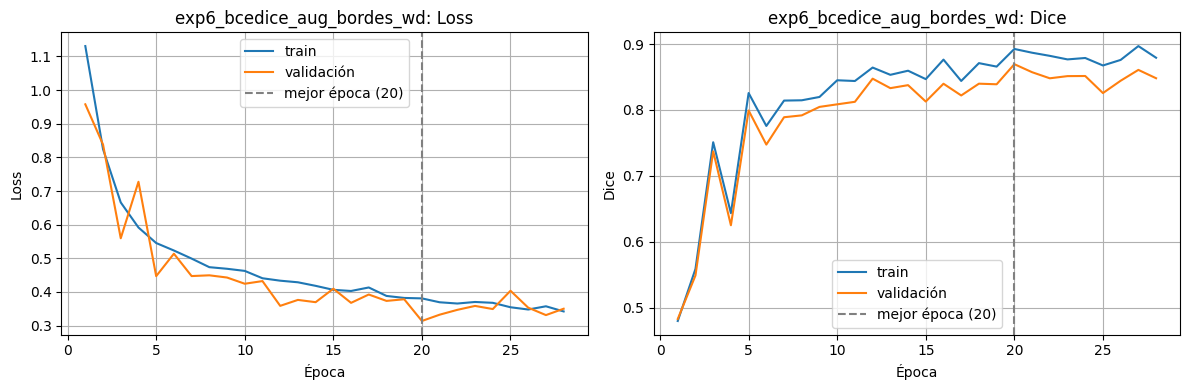

In [ ]:
name_exp6_wd = "exp6_bcedice_aug_bordes_wd"
cfg_exp6_wd = {
    "use_aug": True,
    "dice_weight": 1.0,
    "weight_decay": WEIGHT_DECAY,
    "dropout": 0.0,
    "edge_w0": EDGE_W0,
    "edge_r": EDGE_R
}

print(f"Iniciando el {name_exp6_wd} (contraste + bordes + weight decay {WEIGHT_DECAY})...")
results[name_exp6_wd] = run_experiment(name_exp6_wd, loaders, **cfg_exp6_wd)
plot_history(results[name_exp6_wd], name_exp6_wd)

In [ ]:
# Obtener el modelo del nuevo experimento con Weight Decay
model_exp6_wd = results["exp6_bcedice_aug_bordes_wd"]["model"]

# Predecir sobre las imágenes de prueba y generar RLE
print("Generando predicciones para el test con el modelo del Experimento 6 con Weight Decay...")
ids = sub["id"].astype(str).tolist()
test_files = {Path(p).stem: p for p in test_images}
rles_exp6_wd = [rle_encode(predict_mask(model_exp6_wd, test_files[Path(i).stem])) for i in ids]

# Crear DataFrame de entrega
submission_exp6_wd = pd.DataFrame({"id": sub["id"], "encoded_pixels": rles_exp6_wd})

# Validar que no haya máscaras vacías
assert len(submission_exp6_wd) == len(sub) and (submission_exp6_wd["encoded_pixels"].str.len() > 0).all(), "Error: hay máscaras vacías"

# Guardar archivos
submission_exp6_wd.to_csv("submission_exp6_wd.csv", index=False)
submission_exp6_wd.to_csv("submission.csv", index=False)  # Sobrescribe el principal para descarga directa
print("¡submission_exp6_wd.csv y submission.csv generados con éxito!")
submission_exp6_wd.head()

Generando predicciones para el test con el modelo del Experimento 6 con Weight Decay...
¡submission_exp6_wd.csv y submission.csv generados con éxito!


,id,encoded_pixels
0,0000.png,72074 2 79266 1 79269 1 79271 2 79274 2 79716 ...
1,0001.png,77436 5 77926 9 78416 12 78907 13 79398 15 798...
2,0002.png,63457 14 63964 20 64473 23 64982 25 65491 29 6...
3,0003.png,33631 1 34075 2 34498 1 34514 3 34519 2 34942 ...
4,0004.png,32026 2 32461 3 32896 4 33331 6 33766 8 34201 ...


#### Chequeo previo (≈30 s)

Antes de entrenar se mide cuánto tarda un paso de entrenamiento y el primer batch del loader, y se estima el tiempo por época. Si da minutos por paso o la estimación es de horas por época, algo anda mal (normalmente falta activar la GPU).

In [ ]:
t0 = time.time()
xb, yb = next(iter(loaders["train_aug"]))
t_loader = time.time() - t0

m = UNet(base=BASE).to(DEVICE)
opt, crit = optim.AdamW(m.parameters(), 1e-3), BCEDiceLoss(1.0)
times = []
for _ in range(4):
    t0 = time.time()
    opt.zero_grad()
    crit(m(xb.to(DEVICE)), yb.to(DEVICE)).backward()
    opt.step()
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    times.append(time.time() - t0)

step, n_steps = np.mean(times[1:]), len(loaders["train_aug"])     # se descarta el primer paso (arranque de CUDA)
print(f"1er batch del loader: {t_loader:.2f} s | paso de entrenamiento: {step:.2f} s | pasos por época: {n_steps}")
print(f"≈ {n_steps * step / 60:.1f} min por época (+ evaluación) -> hasta {EPOCHS * n_steps * step / 60:.0f} min por experimento")
del m, opt, xb, yb
if DEVICE == "cuda":
    torch.cuda.empty_cache()

1er batch del loader: 0.12 s | paso de entrenamiento: 0.50 s | pasos por época: 101
≈ 0.8 min por época (+ evaluación) -> hasta 21 min por experimento


In [ ]:
results = globals().get("results", {})      # conserva los resultados ya calculados
for name, cfg in EXPERIMENTS.items():
    if name in results:
        continue
    results[name] = run_experiment(name, loaders, **cfg)
    plot_history(results[name], name)


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


  Época 001 | loss 0.3305 / 0.2146 | Dice 0.2858 / 0.2862  (train / val)


KeyboardInterrupt: 

### 6.3 Análisis de los experimentos

_Completar al ejecutar, mirando las curvas y la tabla de la sección 6.4:_

- **Augmentation (1 → 2):** si sube el Dice de validación y si se achica la brecha entre train y validación.
- **BCE vs BCE + Dice (2 → 3):** si el Dice mejora, y si el modelo deja de subsegmentar lesiones chicas.
- **Weight decay (3 → 4) y dropout (4 → 5):** si ayudan o si hay *underfitting* (como pasó con el dropout en la Tarea 1).
- **Bordes ponderados (3 → 6):** si mejora el Dice y, sobre todo, el Dice de borde (sección 6.5).
- **Sobreajuste:** diferencia entre Dice de train y de validación, y época en la que empieza a subir la loss de validación.

### 6.4 Comparación de experimentos

#### Proyecto de wandb

Para cada corrida quedan registradas las curvas por época de loss y Dice, la configuración y las métricas finales. **Antes de entregar:** verificar que el proyecto sea público y que el link abra sin iniciar sesión.

In [ ]:
try:
    entity = WANDB_ENTITY or wandb.Api().default_entity      # con entity=None, wandb usa la cuenta del usuario logueado
    WANDB_PROJECT_URL = f"https://wandb.ai/{entity}/{WANDB_PROJECT}"
    display(Markdown(f"**Link al proyecto de wandb:** [{WANDB_PROJECT_URL}]({WANDB_PROJECT_URL})"))
except Exception:
    print("No se pudo obtener el link de wandb (sin sesión online). Copiarlo a mano desde wandb.ai antes de entregar.")
if WANDB_MODE != "online":
    print("OJO: esta ejecución fue offline, no hay corridas subidas. Volver a correr en modo online antes de entregar.")


#### Tabla resumen

In [ ]:
rows = []
for name, r in results.items():
    be = r["best_epoch"] - 1
    rows.append({"run": name, "aug": r["config"]["augmentation"], "dice_weight": r["config"]["dice_weight"], "edge_w0": r["config"].get("edge_w0", 0.0),
                 "weight_decay": r["config"]["weight_decay"], "dropout": r["config"]["dropout"],
                 "val_dice": r["val_dice"], "train_dice": r["train_dices"][be],
                 "gap_train_val": r["train_dices"][be] - r["val_dices"][be],
                 "mejor_época": r["best_epoch"], "épocas": r["n_epochs"], "tiempo_s": round(r["train_time_sec"])})

summary_df = pd.DataFrame(rows).set_index("run")
print(f"Hardware: {HARDWARE} | seed={SEED} | batch_size={BATCH_SIZE} | lr={LR} | base={BASE} | img={IMG_SIZE}")
summary_df.round(4)

#### Curvas comparativas

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, r in results.items():
    axes[0].plot(range(1, r["n_epochs"] + 1), r["val_losses"], label=name)
    axes[1].plot(range(1, r["n_epochs"] + 1), r["val_dices"], label=name)
axes[0].set(title="Loss de validación (no comparable entre pérdidas distintas)", xlabel="Época", ylabel="val_loss")
axes[1].set(title="Dice de validación por época", xlabel="Época", ylabel="val_dice")
for ax in axes:
    ax.grid(True)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 6.5 ¿Mejora ponderar los bordes?

Se compara el experimento 6 con el 3 (idéntico salvo por la ponderación de bordes) sobre las mismas imágenes de validación, con dos métricas:

- **Dice** por imagen (la métrica de la competencia).
- **Dice de borde**: Dice restringido a una banda de ±3 px alrededor del contorno manual, que mide la calidad del borde.

Como con una semilla y ≈270 imágenes el Dice varía ±0.01 por azar, se mira la **diferencia pareada** (misma imagen, un modelo contra otro) con su intervalo de confianza aproximado del 95 % (±1.96 errores estándar). Hay mejora si el intervalo queda por encima de 0.

In [ ]:
@torch.no_grad()
def band_dice(model, loader, thr=0.5, r=3):
    """Dice restringido a una banda de ±r px alrededor del contorno manual."""
    model.eval()
    out = []
    for x, y in loader:
        p = (torch.sigmoid(model(x.to(DEVICE))) > thr).float().cpu()
        band = F.max_pool2d(y, 2 * r + 1, 1, r) + F.max_pool2d(-y, 2 * r + 1, 1, r)
        pb, yb = p * band, y * band
        out.append(2 * (pb * yb).sum((1, 2, 3)) / (pb.sum((1, 2, 3)) + yb.sum((1, 2, 3))).clamp(min=1))
    return torch.cat(out).numpy()


REF, NEW = "exp3_bcedice_aug", "exp6_bcedice_aug_bordes"
rows = {}
for metric, fn in [("Dice", dice_per_image), ("Dice de borde (±3 px)", band_dice)]:
    a, b = (fn(results[n]["model"], loaders["val"]) for n in (REF, NEW))
    d = b - a                                         # diferencia pareada por imagen
    ic = 1.96 * d.std() / np.sqrt(len(d))
    rows[metric] = {REF: a.mean(), NEW: b.mean(), "diferencia": d.mean(), "IC95% inf": d.mean() - ic, "IC95% sup": d.mean() + ic,
                    "veredicto": "mejora" if d.mean() - ic > 0 else ("empeora" if d.mean() + ic < 0 else "no concluyente")}
pd.DataFrame(rows).T.round(4)

_Completar al ejecutar:_ si ponderar los bordes mejora el Dice, el Dice de borde o ninguno (veredicto de la tabla), y qué configuración de pérdida se usa para el modelo final. Si no mejora, una posible razón es que en ecografía el borde es difuso y la anotación manual es ruidosa justo ahí.

## 7. Evaluación

_Métricas del modelo elegido en validación, análisis de errores y ejemplos._

El test de Kaggle no tiene máscaras y no se puede analizar, así que la evaluación detallada se hace sobre la **validación** (pacientes que el modelo no vio). Recordar que un buen resultado acá no garantiza uno bueno en test, porque la validación proviene de los mismos equipos que train (sección 8).

### 7.1 Elección del modelo

El modelo final es el de mayor **Dice de validación**.

In [ ]:
best_name = max(results, key=lambda k: results[k]["val_dice"])
best = results[best_name]
best_model = best["model"]

print(f"Modelo elegido: {best_name} | Dice val = {best['val_dice']:.4f}")
print(f"Configuración: {best['config']}")
torch.save(best_model.state_dict(), "unet_best.pt")

### 7.2 Dice en validación: global, por equipo y por patología

In [ ]:
val_dice_img = dice_per_image(best_model, loaders["val"])
val_df = df.iloc[va_idx].assign(dice=val_dice_img)

print(f"Dice medio: {val_dice_img.mean():.4f} | mediana: {np.median(val_dice_img):.4f} | desvío: {val_dice_img.std():.4f}")
print(f"Imágenes con Dice < 0.5: {(val_dice_img < 0.5).mean():.1%} | Dice = 0: {(val_dice_img == 0).sum()} imágenes")

for col in ["device", "pathology"]:
    display(val_df.groupby(col)["dice"].agg(imagenes="count", dice_medio="mean", dice_mediana="median").round(3))

### 7.3 Distribución del Dice y relación con el tamaño de la lesión

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(val_dice_img, bins=25, color="steelblue")
axes[0].axvline(val_dice_img.mean(), color="k", linestyle="--", label="media")
axes[0].set(title="Dice por imagen (validación)", xlabel="Dice", ylabel="imágenes")
axes[0].legend()
for dev, g in val_df.groupby("device"):
    axes[1].scatter(100 * g["lesion_frac"], g["dice"], s=12, alpha=.7, label=dev)
axes[1].set(title="Dice vs tamaño de la lesión", xlabel="% de la imagen ocupado por la lesión", ylabel="Dice", xscale="log")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

val_df["tamaño"] = pd.qcut(val_df["lesion_frac"], 4, labels=["Q1 (más chicas)", "Q2", "Q3", "Q4 (más grandes)"])
val_df.groupby("tamaño", observed=True)["dice"].agg(imagenes="count", dice_medio="mean").round(3)

### 7.4 Ejemplos de segmentaciones correctas e incorrectas

Arriba la máscara manual y abajo la predicción del modelo, para los 5 mejores y los 5 peores casos de validación.

In [ ]:
val_probs = predict_probs(best_model, loaders["val"])        # (N, 1, H, W), mismo orden que va_idx


def show_cases(order, title):
    fig, axes = plt.subplots(2, len(order), figsize=(3.2 * len(order), 6.5), squeeze=False)
    for j, i in enumerate(order):
        g = va_idx[i]
        img = X[g, 0].numpy()
        show_overlay(axes[0, j], img, Y[g, 0].numpy(), f"Manual | {val_df['device'].iloc[i]} | {val_df['pathology'].iloc[i]}")
        show_overlay(axes[1, j], img, (val_probs[i, 0] > 0.5).numpy(), f"Predicción | Dice {val_dice_img[i]:.2f}")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


order = np.argsort(val_dice_img)
show_cases(order[::-1][:5], "Mejores casos de validación")
show_cases(order[:5], "Peores casos de validación")

### 7.5 Análisis de errores

_Completar al ejecutar, mirando las tablas y figuras de 7.2 a 7.4:_

- **Casos difíciles:** qué tienen en común los peores casos (lesiones muy chicas, bordes difusos, sombra acústica, imágenes con varias estructuras oscuras, malignas vs benignas).
- **Tipo de error:** si predominan los falsos negativos (lesión no detectada o subsegmentada) o los falsos positivos (zonas oscuras del tejido segmentadas como lesión).
- **Tamaño de la lesión:** cómo cae el Dice en el cuartil de lesiones más chicas.
- **Por equipo / patología:** si algún equipo o tipo de patología tiene un Dice claramente menor.

## 8. Efecto del cambio de dominio

_Qué pasa cuando el modelo ve un equipo de adquisición que nunca vio en entrenamiento._

El test de Kaggle viene de otros centros y ecógrafos, y no podemos analizarlo. Para **medir el efecto del cambio de dominio con datos propios** simulamos esa situación: se deja **un equipo completo fuera del entrenamiento y de la validación**, se entrena con la configuración ganadora sobre los demás equipos (con su propia validación, por paciente, para el early stopping) y se mide el Dice sobre el equipo excluido. Se compara con el Dice del mismo modelo sobre pacientes de equipos vistos, y con el modelo principal (que sí vio ese equipo) sobre ese mismo equipo.

Se deja afuera el equipo con menos imágenes (`HOLDOUT`) para que el costo sea el de una corrida más; se puede cambiar por cualquier otro equipo.

In [ ]:
HOLDOUT = df["device"].value_counts().index[-1]
ho_idx = np.where(df["device"] == HOLDOUT)[0]
tr2, va2 = split_cases(np.where(df["device"] != HOLDOUT)[0])

loaders_ho = get_loaders(tr2, va2)
loaders_ho["holdout"] = make_loader(ds_eval, ho_idx)
print(f"Equipo excluido: {HOLDOUT} ({len(ho_idx)} imágenes) | train: {len(tr2)} | val (equipos vistos): {len(va2)}")

r_ho = run_experiment(f"holdout_{HOLDOUT}", loaders_ho, **EXPERIMENTS[best_name])
plot_history(r_ho, f"holdout_{HOLDOUT}")

In [ ]:
d_unseen = dice_per_image(r_ho["model"], loaders_ho["holdout"])
d_seen = dice_per_image(r_ho["model"], loaders_ho["val"])
d_ref = val_df.loc[val_df["device"] == HOLDOUT, "dice"]

pd.DataFrame({
    "Dice medio": {f"Modelo sin {HOLDOUT} en {HOLDOUT} (equipo NO visto)": d_unseen.mean(),
                   "Mismo modelo en validación (equipos vistos)": d_seen.mean(),
                   f"Modelo principal en {HOLDOUT} (equipo visto)": d_ref.mean()},
    "imágenes": {f"Modelo sin {HOLDOUT} en {HOLDOUT} (equipo NO visto)": len(d_unseen),
                 "Mismo modelo en validación (equipos vistos)": len(d_seen),
                 f"Modelo principal en {HOLDOUT} (equipo visto)": len(d_ref)},
}).round(3)

_Completar al ejecutar:_

- **Cuánto cae el Dice** con un equipo no visto respecto de los equipos vistos, y por qué (diferencias de brillo, contraste, ruido *speckle* y resolución mostradas en la sección 3.3).
- **Qué imágenes se segmentan peor** en el equipo excluido (ver los gráficos de 7.3 y 7.4) y qué implica para el test, donde **todos** los equipos son nuevos.
- **Qué ayudaría a generalizar** (no probado acá): augmentation de intensidad (brillo, contraste, gamma), normalización por imagen, más épocas con regularización y entrenar con todos los datos.

## 9. Competencia Kaggle

_Predicción sobre el test oculto, RLE y archivo de envío._

Pasos:

1. Se lee cada imagen de test, se lleva a 256×256 y se normaliza con **la media y el desvío de train** (`eval_transforms`).
2. Se predice con el modelo elegido y *test-time augmentation* con flip horizontal (se promedian las probabilidades de la imagen y de su espejo).
3. La probabilidad se **escala al tamaño original** de la imagen (interpolación bilineal) y se binariza en 0.5.
4. Si una máscara queda vacía, Kaggle rechaza el envío completo: en ese caso se usa el umbral `0.5 · max(prob)`, que garantiza al menos un píxel.
5. Se codifica con **RLE** (orden Fortran, índices desde 1) y se arma `submission.csv` con las columnas `id` y `encoded_pixels`.

Límite: 2 envíos por día, y hay que seleccionar 2 envíos para la evaluación final.

In [ ]:
def rle_encode(mask):
    pixels = np.array(mask).flatten(order="F")              # orden Fortran
    pixels = np.concatenate([[0], pixels, [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1       # transiciones
    runs[1::2] = runs[1::2] - runs[::2]                     # longitudes
    return " ".join(str(x) for x in runs)


def rle_decode(s, shape):
    v = np.array(s.split(), dtype=int)
    flat = np.zeros(shape[0] * shape[1], np.uint8)
    for start, length in zip(v[0::2] - 1, v[1::2]):
        flat[start:start + length] = 1
    return flat.reshape(shape, order="F")


# comprobaciones: ejemplo de la consigna y ida y vuelta con una máscara real de validación
ejemplo = np.array([[0, 0, 1, 0, 0], [0, 1, 1, 1, 0], [1, 1, 1, 0, 0], [0, 0, 0, 1, 1]])
assert rle_encode(ejemplo) == "3 1 6 2 9 3 14 1 16 1 20 1"
m_real = (np.array(Image.open(df["mask_path"].iloc[va_idx[0]]).convert("L")) > 127).astype(np.uint8)
assert (rle_decode(rle_encode(m_real), m_real.shape) == m_real).all()
print("RLE verificado")

In [ ]:
test_files = {Path(p).stem: p for p in test_images}


@torch.no_grad()
def predict_mask(model, path, thr=0.5):
    """Máscara binaria (alto, ancho) con el tamaño original de la imagen."""
    model.eval()
    with Image.open(path) as im:
        w, h = im.size
        x = torch.from_numpy(np.array(im.convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)))[None]   # (1, H, W) uint8
    x = eval_transforms(tv_tensors.Image(x)).as_subclass(torch.Tensor)[None].to(DEVICE)                      # (1, 1, H, W)
    p = (torch.sigmoid(model(x)) + torch.sigmoid(model(x.flip(-1))).flip(-1)) / 2                           # TTA: flip horizontal
    p = F.interpolate(p, size=(h, w), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
    mask = p > thr
    if not mask.any():                                                                                      # Kaggle rechaza máscaras vacías
        mask = p >= 0.5 * p.max()
    return mask.astype(np.uint8)


ids = sub["id"].astype(str).tolist()
rles = [rle_encode(predict_mask(best_model, test_files[Path(i).stem])) for i in ids]

submission = pd.DataFrame({"id": sub["id"], "encoded_pixels": rles})
assert len(submission) == len(sub) and (submission["encoded_pixels"].str.len() > 0).all(), "hay máscaras vacías"
submission.to_csv("submission.csv", index=False)
print(f"submission.csv generado con {len(submission)} filas")
submission.head()

## 10. Conclusiones

_Qué funcionó, qué no, y qué haríamos distinto con más tiempo o recursos. Completar al ejecutar con los resultados reales:_

**Qué funcionó.** Qué experimento ganó y por cuánto; si el augmentation de la Tarea 1 (sin deformaciones elásticas) y la pérdida BCE + Dice aportaron respecto del baseline.

**Qué no funcionó.** Qué técnicas no mejoraron (por ejemplo, weight decay o dropout) y por qué.

**Cambio de dominio.** Cuánto cae el Dice con un equipo no visto (sección 8) y qué implica para el puntaje en la tabla pública de Kaggle. Puntaje obtenido en Kaggle: _completar_.

**Qué haríamos con más tiempo.** Augmentation de intensidad para cubrir diferencias entre ecógrafos, `base=64` como en el paper, reentrenar con train + validación, ajustar el umbral de binarización, y comparar contra deformaciones elásticas.